<a href="https://colab.research.google.com/github/ayuannisa17/PCdVK_ganjil_2026/blob/main/minggu7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. TUGAS PRAKTIKUM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from google.colab import drive
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

from skimage import data
from skimage.filters import threshold_otsu
from skimage import color, segmentation, feature, morphology
from skimage.segmentation import flood

##3. Global Threshold manual

ukuran citra: (250, 445)
rentang nilai: 0 - 255


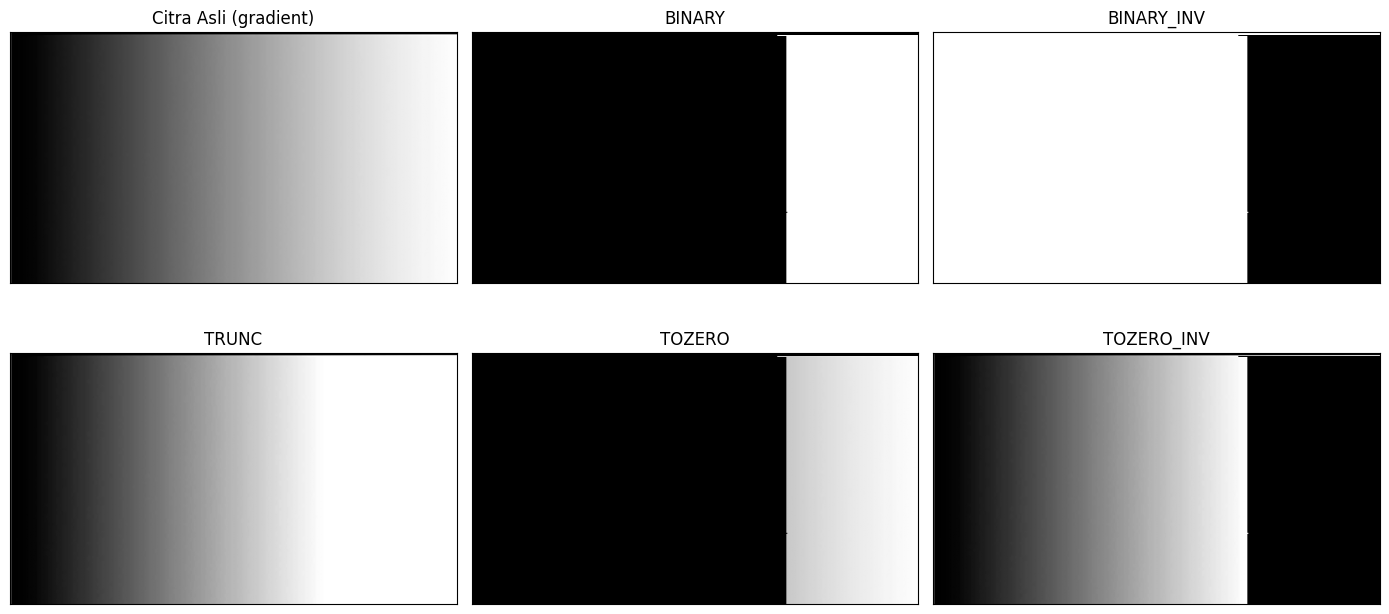

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra gradient
filename = '/content/drive/MyDrive/PCdVK/gradient.png'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

# Cek gambar berhasil dibaca
if img is None:
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Periksa nama dan lokasi file gradient.jpg."
    )

print('ukuran citra:', img.shape)
print('rentang nilai:', img.min(), '-', img.max())

thresh = 200
maxval = 255

# Global Threshold manual
def threshold_manual(src, thresh, maxval, jenis):
    s = src.astype(np.int32)

    if jenis == 'BINARY':
        return np.where(s > thresh, maxval, 0).astype(np.uint8)
    if jenis == 'BINARY_INV':
        return np.where(s > thresh, 0, maxval).astype(np.uint8)
    if jenis == 'TRUNC':
        return np.where(s > thresh, thresh, s).astype(np.uint8)
    if jenis == 'TOZERO':
        return np.where(s > thresh, s, 0).astype(np.uint8)
    if jenis == 'TOZERO_INV':
        return np.where(s > thresh, 0, s).astype(np.uint8)

    raise ValueError('Jenis tidak dikenal: ' + jenis)

jenis_threshold = [
    'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV'
]

hasil_manual = [
    threshold_manual(img, thresh, maxval, jenis)
    for jenis in jenis_threshold
]

# Menampilkan hasil
titles = ['Citra Asli (gradient)'] + jenis_threshold
images = [img] + hasil_manual

plt.figure(figsize=(14, 7))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

##4. program Addaptive Threshold

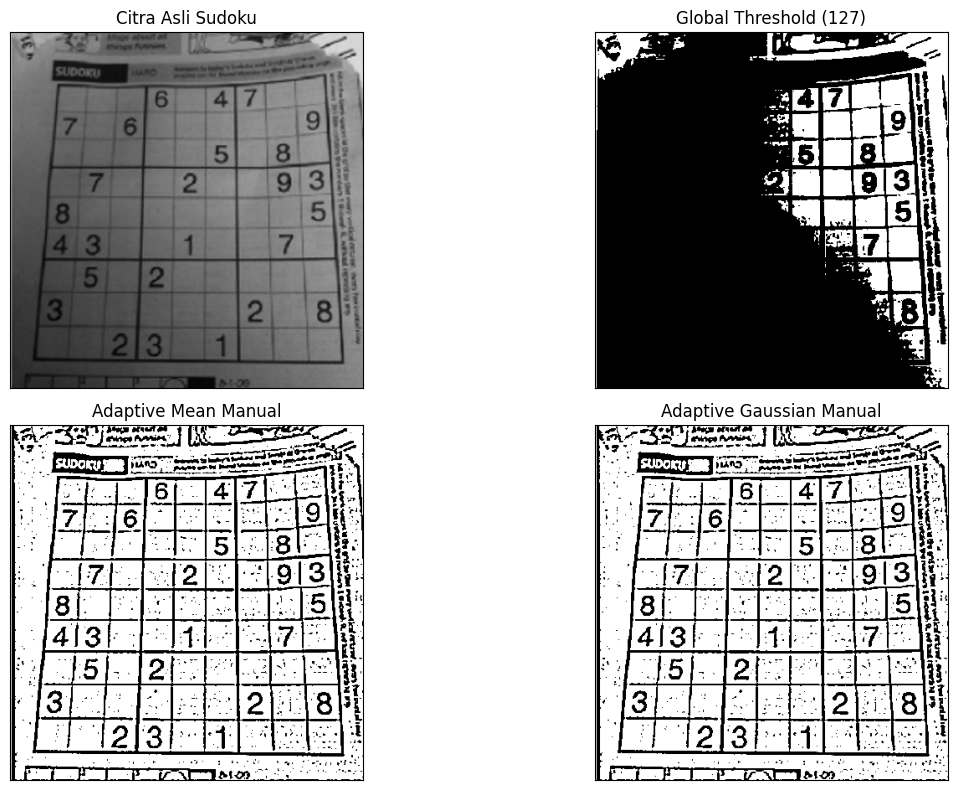

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra Sudoku
filename = '/content/drive/MyDrive/PCdVK/sudoku.png'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "Citra Sudoku tidak ditemukan. Periksa nama dan lokasi file."
    )

# Parameter
thresh = 127
block_size = 11
C = 2
sigma = 2

# Menghitung threshold global secara manual
global_binary = np.where(img > thresh, 255, 0).astype(np.uint8)

# Membuat padding agar ukuran citra tetap
pad = block_size // 2
padded = np.pad(img.astype(np.float64), pad, mode='reflect')

# Membuat kernel Gaussian manual
x = np.arange(-pad, pad + 1)
X, Y = np.meshgrid(x, x)

kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
kernel = kernel / kernel.sum()

# Menghitung rata-rata lokal menggunakan Gaussian
local_mean = np.zeros(img.shape, dtype=np.float64)

for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        window = padded[i:i + block_size, j:j + block_size]
        local_mean[i, j] = np.sum(window * kernel)

# Adaptive Threshold Mean manual
adaptive_mean = np.where(
    img > local_mean - C, 255, 0
).astype(np.uint8)

# Adaptive Threshold Gaussian manual
adaptive_gaussian = np.where(
    img > local_mean - C, 255, 0
).astype(np.uint8)

# Menampilkan hasil
titles = [
    'Citra Asli Sudoku',
    'Global Threshold (127)',
    'Adaptive Mean Manual',
    'Adaptive Gaussian Manual'
]

images = [img, global_binary, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(14, 8))

for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

##5.  Otsu Thresholding

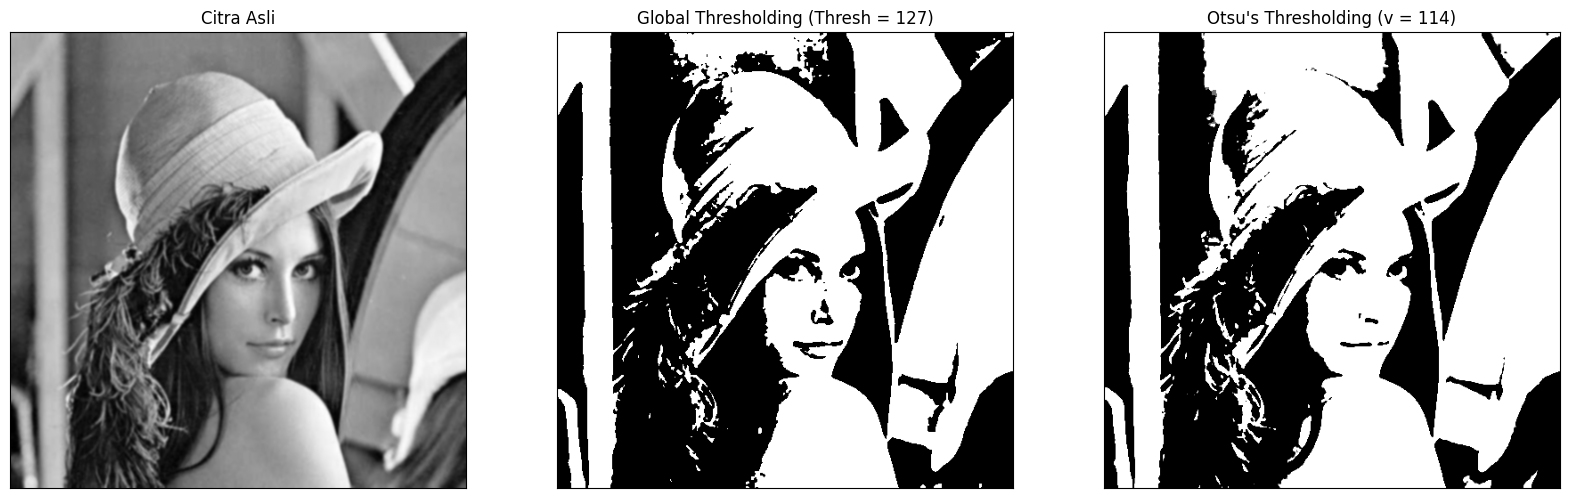

In [32]:
# a. citra lenna
filename = '/content/drive/MyDrive/PCdVK/lenna.jpg'
img = cv.imread(filename, 0)

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
]

citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

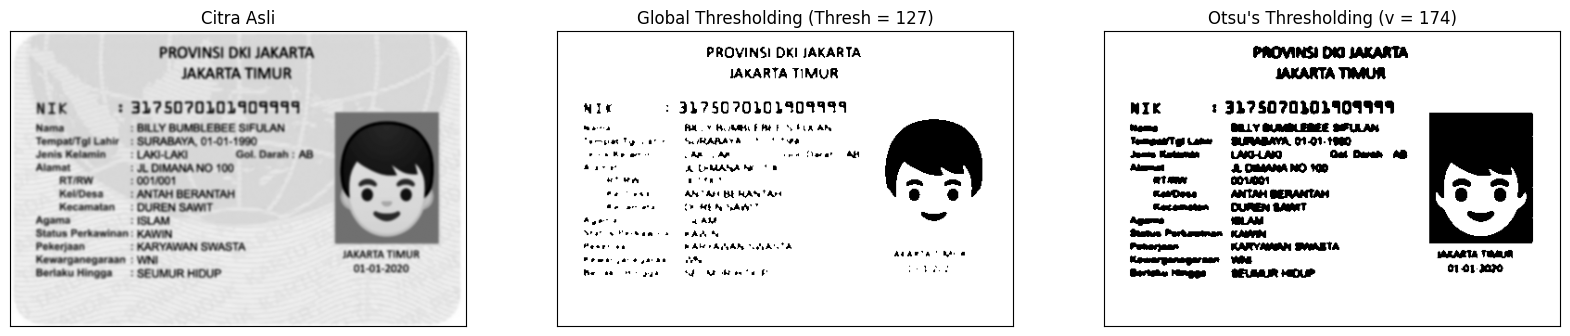

In [33]:
# b. citra ktp
filename = '/content/drive/MyDrive/PCdVK/ktp.png'
img = cv.imread(filename, 0)

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = ' + str(thresh) + ')',
    "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
]

citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

##6. (a) Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage

Seed (baris, kolom): (36, 43)
Intensitas: 159


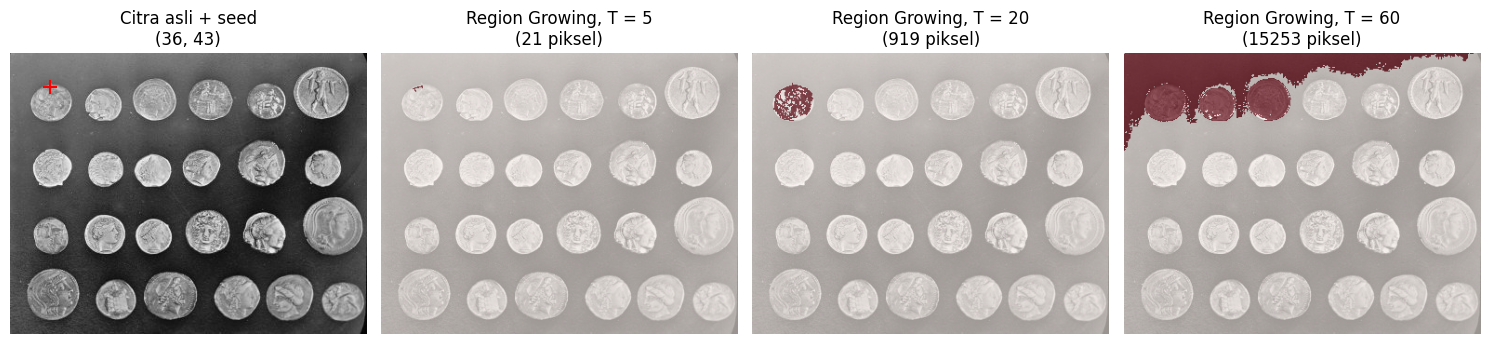

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Membaca citra koin
gray = data.coins()

# Seed sesuai contoh modul (baris, kolom)
seed = (36, 43)

# Mengambil intensitas pada seed
intensitas = gray[seed]

print('Seed (baris, kolom):', seed)
print('Intensitas:', intensitas)

# Toleransi region growing
tolerances = [5, 20, 60]

# Menampilkan citra asli dan hasil segmentasi
plt.figure(figsize=(15, 5))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], color='red', marker='+', s=100)
plt.title(f'Citra asli + seed\n{seed}')
plt.axis('off')

# Region growing untuk setiap toleransi
for i, tolerance in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tolerance,
        connectivity=1
    )

    plt.subplot(1, 4, i + 2)
    plt.imshow(gray, cmap='gray')
    plt.imshow(region, cmap='Reds', alpha=0.6)
    plt.title(
        f'Region Growing, T = {tolerance}\n'
        f'({np.sum(region)} piksel)'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

##(b) Gunakan skimage.segmentation.flood().

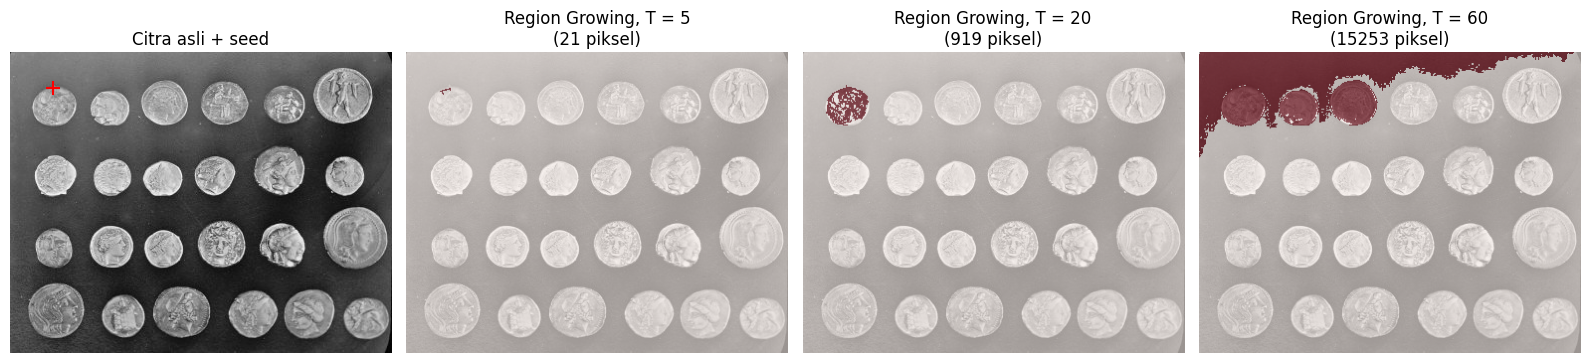

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Membaca citra koin
gray = data.coins()

# Seed (baris, kolom)
seed = (36, 43)

# Segmentasi menggunakan fungsi siap pakai
tolerances = [5, 20, 60]

plt.figure(figsize=(16, 5))

# Citra asli dan seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], color='red', marker='+', s=100)
plt.title('Citra asli + seed')
plt.axis('off')

# Region growing dengan variasi tolerance
for i, tolerance in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tolerance,
        connectivity=1
    )

    plt.subplot(1, 4, i + 2)
    plt.imshow(gray, cmap='gray')
    plt.imshow(region, cmap='Reds', alpha=0.6)
    plt.title(
        f'Region Growing, T = {tolerance}\n'
        f'({np.sum(region)} piksel)'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

##7. Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang biru saja.

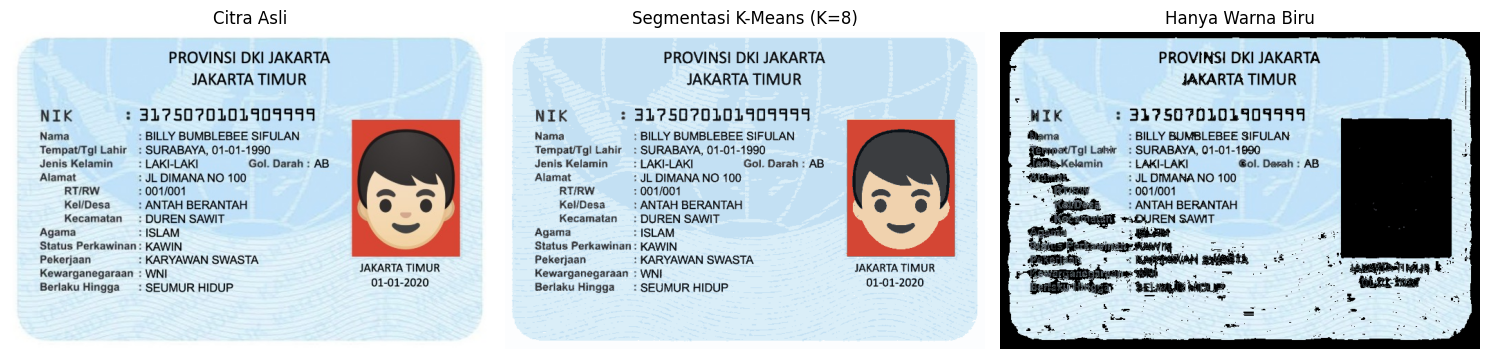

In [45]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Membaca citra KTP
filename = '/content/drive/MyDrive/PCdVK/ktp_fulan.jpeg'
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(
        "File ktp_fulan.jpg tidak ditemukan di folder PCVK."
    )

# Konversi warna BGR ke HSV
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
H, S, V = cv.split(hsv)

# Segmentasi warna menggunakan K-Means (K=8)
pixel_values = img.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixel_values)

centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels].reshape(img.shape)

# Rentang warna biru sesuai modul
kelompok_biru = np.where(
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

# Membuat citra yang hanya menampilkan warna biru
mask = np.zeros(H.shape, dtype=np.uint8)
mask[kelompok_biru] = 255

hasil_biru = cv.bitwise_and(img, img, mask=mask)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(segmented, cv.COLOR_BGR2RGB))
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(hasil_biru, cv.COLOR_BGR2RGB))
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

# D2 TUGAS KELOMPOK OCR

In [47]:
!pip install pytesseract
!apt-get install -y tesseract-ocr tesseract-ocr-ind

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
The following NEW packages will be installed:
  tesseract-ocr-ind
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 590 kB of archives.
After this operation, 1,138 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 tesseract-ocr-ind all 1:4.1.0-2 [590 kB]
Fetched 590 kB in 2s (383 kB/s)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


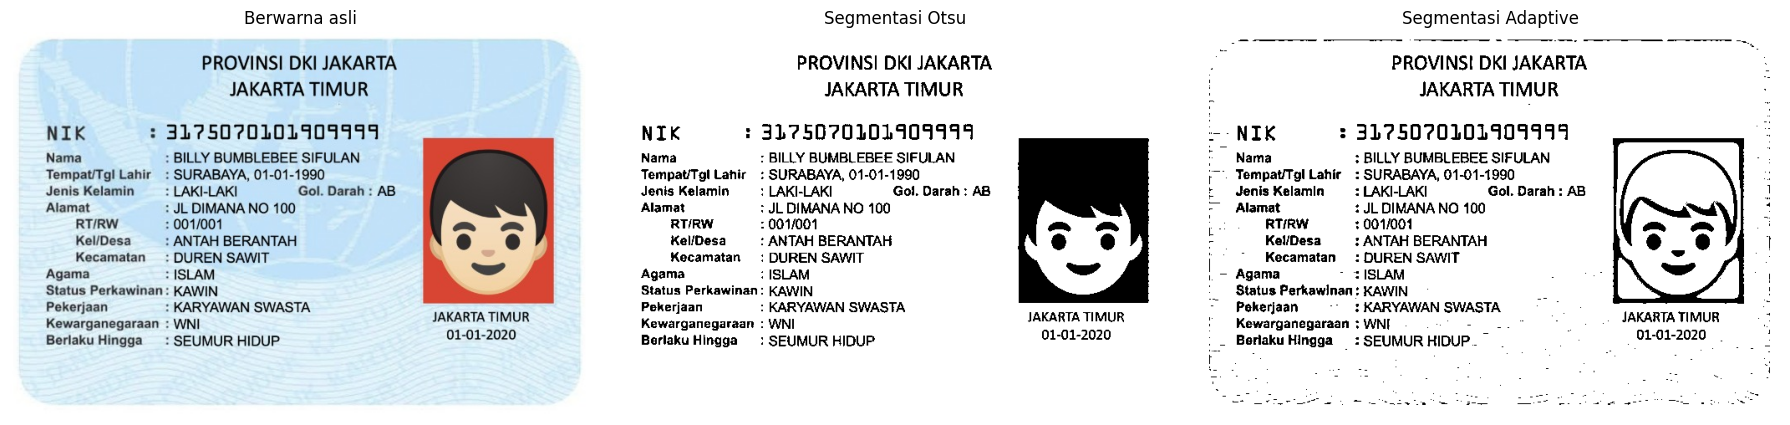

Berwarna asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020
Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020
Segmentasi Adaptive
ai PROVINSI DKI JAKARTA 1
| JAKARTA TIMUR 1
-- NIK 1 32950?0101999444 :
£ Nama 3 BILLY BUMBLEBEE SIFULAN

—- Tempa

In [48]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

# Pengaturan OCR
BAHASA = 'ind'
PSM = 6

# Membaca citra KTP
filename = '/content/drive/MyDrive/PCdVK/ktp_fulan.jpeg'
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(
        "Citra ktp_fulan.jpeg tidak ditemukan di folder PCdVK."
    )

# Mengubah citra menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. Citra berwarna asli
citra_asli = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Segmentasi Otsu
_, otsu = cv.threshold(
    gray, 0, 255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# 3. Segmentasi Adaptive
adaptive = cv.adaptiveThreshold(
    gray, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    31, 15
)

# Menggabungkan ketiga citra
citra_ocr = {
    'Berwarna asli': citra_asli,
    'Segmentasi Otsu': otsu,
    'Segmentasi Adaptive': adaptive
}

# Menampilkan ketiga citra
plt.figure(figsize=(18, 5))

for i, (nama, gambar) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1)

    if gambar.ndim == 3:
        plt.imshow(gambar)
    else:
        plt.imshow(gambar, cmap='gray')

    plt.title(nama)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Membaca teks dari ketiga citra
teks = {}

for nama, gambar in citra_ocr.items():
    teks[nama] = pytesseract.image_to_string(
        gambar,
        lang=BAHASA,
        config='--psm 6'
    )

    print('=' * 50)
    print(nama)
    print('=' * 50)
    print(teks[nama].strip())

##3. Tampilkan area teks yang dikenali z

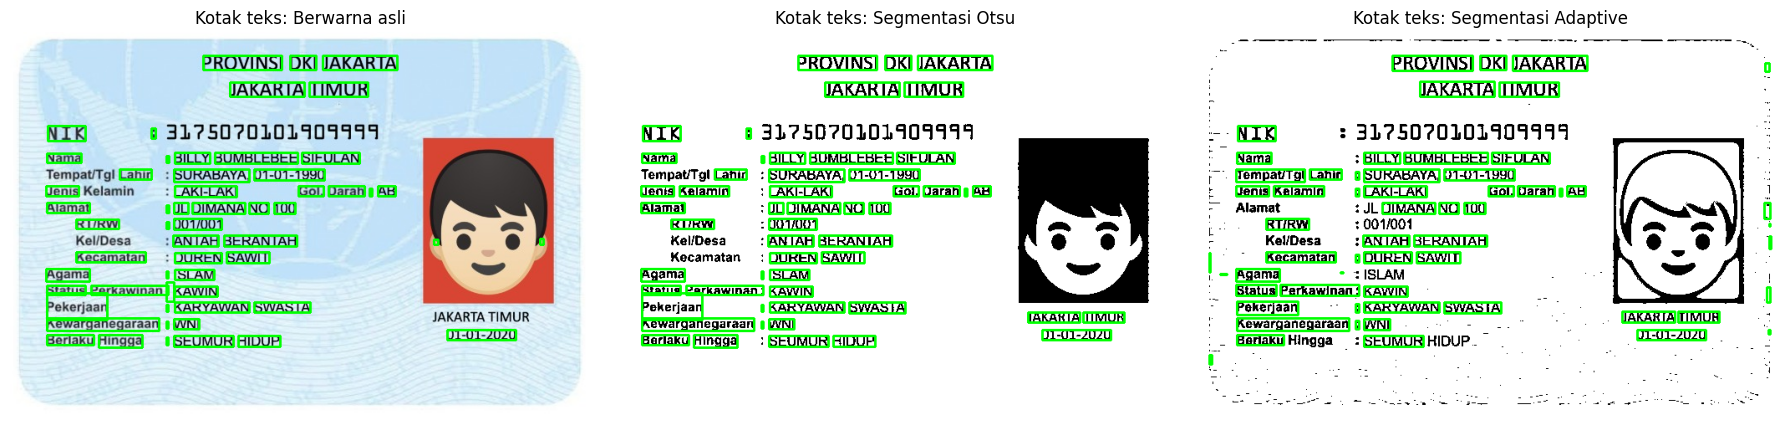

In [49]:
def kotak_teks(img, conf_min=60):
    data = pytesseract.image_to_data(
        img,
        lang=BAHASA,
        config='--psm 6',
        output_type=pytesseract.Output.DICT
    )

    if img.ndim == 2:
        hasil = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    else:
        hasil = cv.cvtColor(img, cv.COLOR_RGB2BGR)

    for i, txt in enumerate(data['text']):
        if not txt.strip():
            continue

        try:
            conf = float(data['conf'][i])
        except (ValueError, TypeError):
            continue

        if conf > conf_min:
            x = data['left'][i]
            y = data['top'][i]
            w = data['width'][i]
            h = data['height'][i]

            cv.rectangle(
                hasil,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    return cv.cvtColor(hasil, cv.COLOR_BGR2RGB)


plt.figure(figsize=(18, 5))

for i, (nama, gambar) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(kotak_teks(gambar))
    plt.title('Kotak teks: ' + nama)
    plt.axis('off')

plt.tight_layout()
plt.show()

##4. bandingkan hasil pembacaan

In [50]:
# Teks sebenarnya yang dijadikan acuan
acuan = [
    '3175070101909999',
    'BILLY BUMBLEBEE SIFULAN',
    'SURABAYA',
    '01-01-1990',
    'LAKI-LAKI',
    'ISLAM',
    'KARYAWAN SWASTA',
    'JL DIMANA NO 100',
    'SEUMUR HIDUP',
    'DUREN SAWIT'
]

# Menyamakan huruf besar/kecil dan spasi
def normal(teks):
    return ' '.join(teks.upper().split())

# Membandingkan hasil OCR dengan teks acuan
data_tabel = []

for nama, hasil_ocr in teks.items():
    hasil_normal = normal(hasil_ocr)

    baris = {'Teks sebenarnya': acuan}

    for item in acuan:
        baris[item] = item in hasil_normal

    data_tabel.append({
        'Citra masukan OCR': nama,
        'Hasil OCR': hasil_ocr.strip(),
        'Item terbaca tepat': sum(baris[item] for item in acuan),
        'Kecocokan (%)': round(
            100 * sum(baris[item] for item in acuan) / len(acuan), 1
        )
    })

# Menampilkan tabel ringkasan
df_hasil = pd.DataFrame(data_tabel)

display(
    df_hasil[
        ['Citra masukan OCR', 'Item terbaca tepat', 'Kecocokan (%)']
    ]
)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%)
0,Berwarna asli,9,90.0
1,Segmentasi Otsu,9,90.0
2,Segmentasi Adaptive,9,90.0


##5. menghitung presentase kecocokkan

In [51]:
hasil_ringkasan = []

for nama, gambar in citra_ocr.items():
    data = pytesseract.image_to_data(
        gambar,
        lang=BAHASA,
        config='--psm 6',
        output_type=pytesseract.Output.DICT
    )

    confidence = []

    for conf, txt in zip(data['conf'], data['text']):
        if txt.strip():
            try:
                nilai = float(conf)
                if nilai >= 0:
                    confidence.append(nilai)
            except (ValueError, TypeError):
                pass

    rata_conf = (
        round(np.mean(confidence), 2)
        if confidence else 0
    )

    hasil_ringkasan.append({
        'Citra masukan OCR': nama,
        'Rata-rata confidence': rata_conf
    })

df_conf = pd.DataFrame(hasil_ringkasan)

# Menggabungkan kecocokan dan confidence
df_ringkasan = df_hasil[
    ['Citra masukan OCR', 'Item terbaca tepat', 'Kecocokan (%)']
].merge(df_conf, on='Citra masukan OCR')

display(df_ringkasan)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,9,90.0,81.19
1,Segmentasi Otsu,9,90.0,78.95
2,Segmentasi Adaptive,9,90.0,64.65


# PERTANYAAN ANALISIS:
1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
- Ketiga citra menghasilkan tingkat kecocokan sebesar 90%. Namun, metode Otsu memiliki rata-rata confidence tertinggi, yaitu 80,21, dibandingkan citra asli sebesar 78,86 dan metode Adaptive sebesar 64,31. Jadi, Otsu menghasilkan tingkat keyakinan pembacaan OCR paling tinggi.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
- Kesalahan pertama terdapat pada bagian NIK yang tidak terbaca sesuai dengan nomor aslinya, yaitu 3175070101909999. Kesalahan kedua terdapat pada tulisan RT/RW di hasil segmentasi Adaptive yang terbaca menjadi 20011001. Kesalahan tersebut menunjukkan bahwa OCR masih dapat keliru mengenali angka dan karakter.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
- Tidak. Berdasarkan hasil percobaan, citra asli, hasil Otsu, dan hasil Adaptive sama-sama memperoleh tingkat kecocokan sebesar 90%. Artinya, segmentasi tidak meningkatkan ketepatan pembacaan OCR pada percobaan ini. Hasil segmentasi dapat membantu memperjelas teks, tetapi belum tentu menghasilkan pembacaan yang lebih tepat.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
- Warna, pola, dan gradasi pada latar belakang dapat mengganggu proses pengenalan teks karena perbedaan antara tulisan dan latar belakang menjadi kurang jelas. Metode segmentasi dapat membantu memisahkan teks dari latar belakang. Namun, jika proses thresholding kurang sesuai, sebagian karakter bisa hilang atau berubah sehingga hasil OCR menjadi kurang akurat.
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki tingkat kecocokan tertinggi? Jelaskan.
- Tidak. Metode Otsu memiliki rata-rata confidence tertinggi sebesar 80,21, tetapi tingkat kecocokannya tetap sama dengan citra asli dan metode Adaptive, yaitu 90%. Hal ini menunjukkan bahwa nilai confidence yang tinggi menandakan OCR lebih yakin terhadap hasil pembacaannya, tetapi tidak selalu berarti hasil tersebut paling benar.

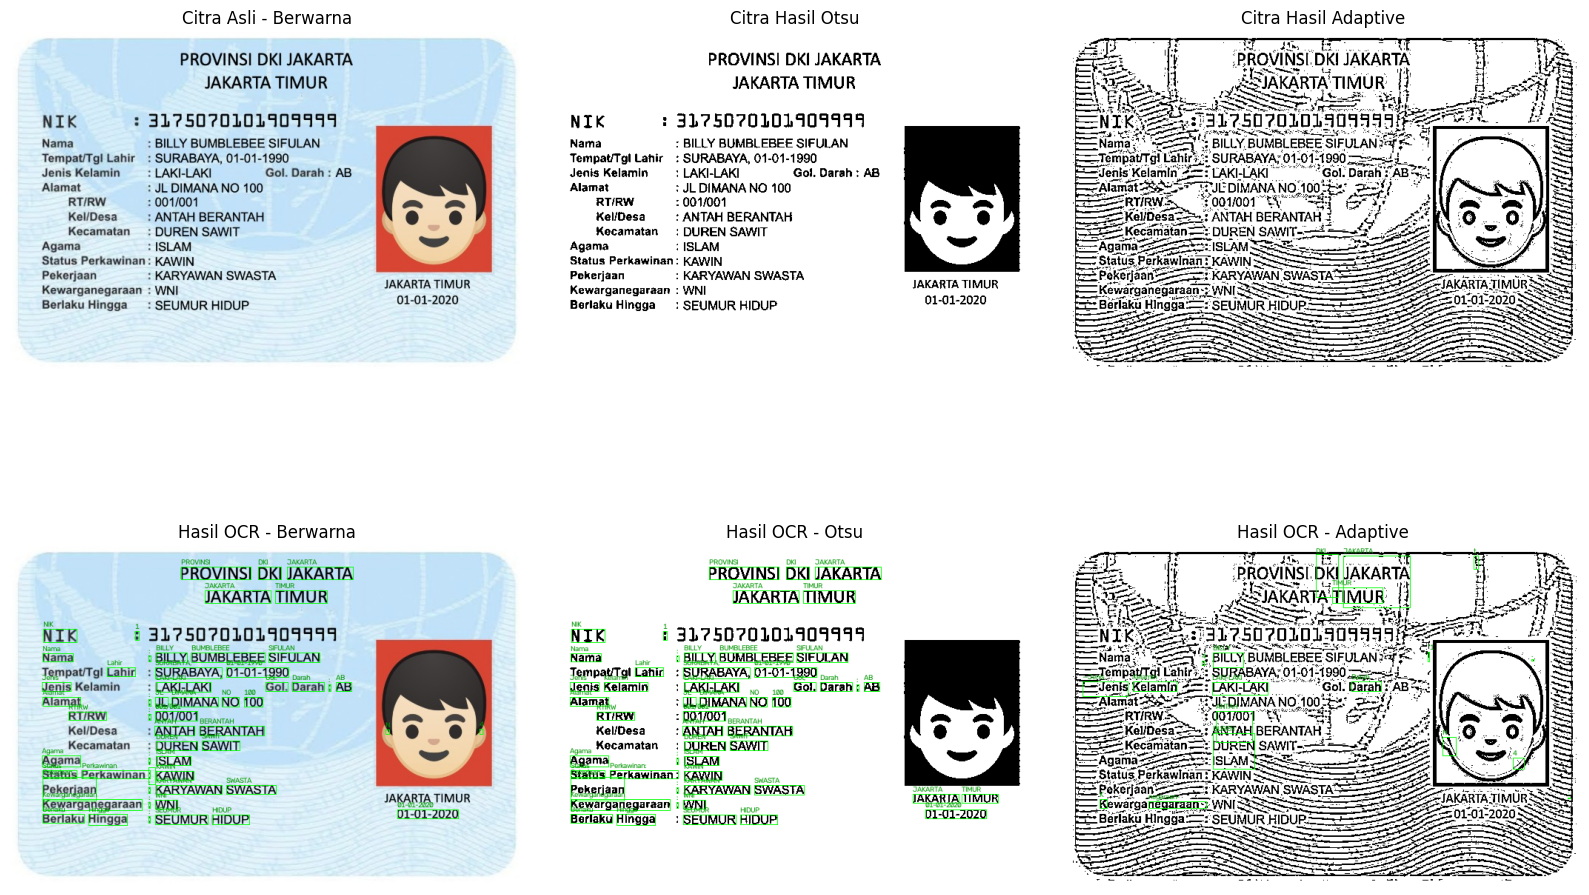

HASIL PEMBACAAN CITRA BERWARNA
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


HASIL PEMBACAAN CITRA OTSU
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


HASIL PEMBACAAN CITRA ADAPTIVE
AE: - Hn INN Anna t 5-3
- PROVINSI DKI JAKARTA F Is
Es, N SSJAKARTA TIM

In [54]:
import cv2
import pytesseract
import matplotlib.pyplot as plt
from pytesseract import Output

# Membaca citra KTP berwarna
path = '/content/drive/MyDrive/PCdVK/ktp_fulan.jpeg'
img = cv2.imread(path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Segmentasi Otsu
_, otsu = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Segmentasi Adaptive
adaptive = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

# Fungsi OCR dan menggambar kotak teks
def tampilkan_ocr(citra, judul, berwarna=False):
    hasil = cv2.cvtColor(citra, cv2.COLOR_GRAY2RGB) if len(citra.shape) == 2 else cv2.cvtColor(citra, cv2.COLOR_BGR2RGB)

    data = pytesseract.image_to_data(
        citra,
        lang='ind',
        config='--psm 6',
        output_type=Output.DICT
    )

    for i in range(len(data['text'])):
        teks = data['text'][i].strip()

        try:
            conf = float(data['conf'][i])
        except ValueError:
            continue

        if teks and conf > 60:
            x, y = data['left'][i], data['top'][i]
            w, h = data['width'][i], data['height'][i]

            cv2.rectangle(
                hasil, (x, y), (x + w, y + h),
                (0, 255, 0), 1
            )

            cv2.putText(
                hasil, teks, (x, max(y - 3, 10)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.35,
                (0, 150, 0), 1
            )

    plt.imshow(hasil)
    plt.title(judul)
    plt.axis('off')

    teks_ocr = pytesseract.image_to_string(
        citra, lang='ind', config='--psm 6'
    )
    return teks_ocr


# Menampilkan tiga hasil OCR
plt.figure(figsize=(16, 12))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli - Berwarna')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(otsu, cmap='gray')
plt.title('Citra Hasil Otsu')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(adaptive, cmap='gray')
plt.title('Citra Hasil Adaptive')
plt.axis('off')

plt.subplot(2, 3, 4)
teks_berwarna = tampilkan_ocr(img, 'Hasil OCR - Berwarna')

plt.subplot(2, 3, 5)
teks_otsu = tampilkan_ocr(otsu, 'Hasil OCR - Otsu')

plt.subplot(2, 3, 6)
teks_adaptive = tampilkan_ocr(adaptive, 'Hasil OCR - Adaptive')

plt.tight_layout()
plt.show()

print("HASIL PEMBACAAN CITRA BERWARNA")
print(teks_berwarna)

print("\nHASIL PEMBACAAN CITRA OTSU")
print(teks_otsu)

print("\nHASIL PEMBACAAN CITRA ADAPTIVE")
print(teks_adaptive)